In [1]:
from datasets import load_dataset, concatenate_datasets

ds = concatenate_datasets([
    (
        load_dataset("ylecun/mnist", split="train")
        .remove_columns("label")
        .add_column("label", column=[0] * 60_000)
    ),
    (
        load_dataset("zalando-datasets/fashion_mnist", split="train")
        .remove_columns("label")
        .add_column("label", column=[1] * 60_000)
    )
]).shuffle(seed=42)
ds

Dataset({
    features: ['image', 'label'],
    num_rows: 120000
})

In [2]:
import torchvision.transforms.v2 as transforms

transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor()
])

def pil_to_np(batch):
    batch["image"] = transform(batch["image"])[0]
    return batch

ds = ds.with_transform(pil_to_np)

/Users/ethankim8683/Machine Learning/learning-neural-networks/.venv/lib/python3.13/site-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


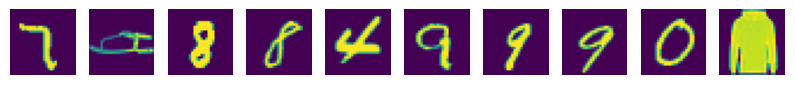

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 10, figsize=(10, 1))
for i in range(10):
    ax[i].imshow(ds[i]["image"])
    ax[i].axis("off")

In [4]:
import torch.nn as nn
import torch

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 1),
    nn.Sigmoid()
)
model(torch.randn((1, 28, 28)))

tensor([[0.3611]], grad_fn=<SigmoidBackward0>)

Surprisal is how surprised a model should be if something turned out to be true. It looks like $-\log(p)$, where $p$ is the probability the model assigned of something being true. Cross-entropy loss works because it's effectively just how surprised the model should be that the true label ended up being true. Based on this logic, I imagine binary cross-entropy should be $y(-\log(p))+(1-y)(-\log(1-p))$, where $y$ is the true label.

In [5]:
from torch.utils.data import DataLoader
from tqdm import tqdm

EPOCHS = 3
EPS = 1e-5
EMA_ALPHA = 0.98

optim = torch.optim.Adam(model.parameters())

def loss_fn(p, y):
    p = torch.clamp(p, EPS, 1 - EPS)
    return y * -p.log() + (1 - y) * -(1 - p).log()

dl = DataLoader(ds, batch_size=32, shuffle=True)

loss_ema = None
for _ in range(EPOCHS):
    with tqdm(dl) as pbar:
        for batch in pbar:
            p = model(batch["image"])
            loss = loss_fn(p, batch["label"])

            optim.zero_grad()
            loss.backward()
            optim.step()

            loss_ema = loss if loss_ema is None else EMA_ALPHA * loss_ema + (1 - EMA_ALPHA) * loss
            pbar.set_postfix({"loss": loss_ema})

100%|██████████| 3750/3750 [00:06<00:00, 586.97it/s, loss=tensor([[0.0101]], grad_fn=<AddBackward0>)]


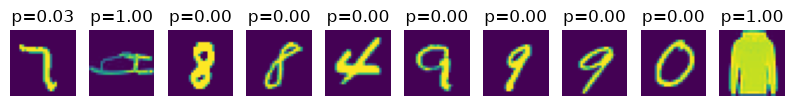

In [6]:
fig, ax = plt.subplots(1, 10, figsize=(10, 1))
for i in range(10):
    ax[i].set_title(f"p={model(ds[i]["image"][None]).item():.2f}")
    ax[i].imshow(ds[i]["image"])
    ax[i].axis("off")

In [7]:
ds_test = concatenate_datasets([
    (
        load_dataset("ylecun/mnist", split="test")
        .remove_columns("label")
        .add_column("label", column=[0] * 10_000)
    ),
    (
        load_dataset("zalando-datasets/fashion_mnist", split="test")
        .remove_columns("label")
        .add_column("label", column=[1] * 10_000)
    )
])
ds_test

Dataset({
    features: ['image', 'label'],
    num_rows: 20000
})

In [8]:
ds_test = ds_test.with_transform(pil_to_np)

100%|██████████| 625/625 [00:00<00:00, 1170.24it/s]


(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'BinaryROC'}, xlabel='False positive rate', ylabel='True positive rate'>)

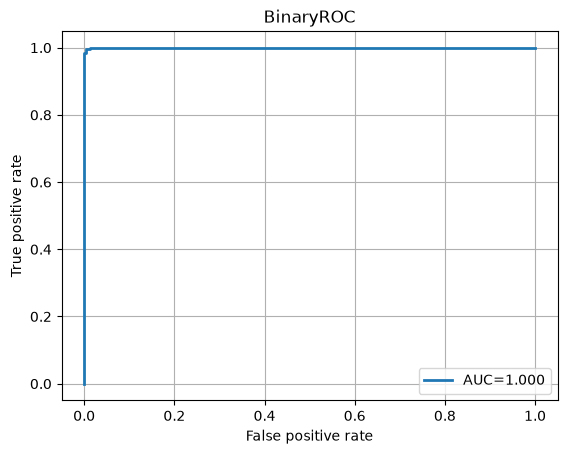

In [9]:
from torchmetrics.classification import BinaryROC

dl_test = DataLoader(ds_test, batch_size=32)

roc = BinaryROC()
with torch.no_grad():
    with tqdm(dl_test) as pbar:
        for batch in pbar:
            p = model(batch["image"])
            roc.update(p, batch["label"][None])
roc.compute()
roc.plot(score=True)

As you can imagine, it's pretty hard to get clothes and numbers mixed up, so the model obviously gets an AUROC of 1.